# Phase 3: checking the Digital Twin and exploring its data

This notebook checks that the calibrated Digital Twin behaves like a real boiler feed pump and decides how the sensor readings should be prepared for the RL agent

The data comes from `python -m scripts.simulate_twin`. Run it once from the repository root before running this notebook

- `data/twin_runs.csv`: 500 runs from a new pump to its first failure, one row per week (EDA seeds 6000 to 6499)
- `data/twin_lives.csv`: lifetimes of each failure mode on its own (the other mode switched off), under the normal load chain and at each fixed load

No maintenance is done in these runs. Maintenance policies come in Phases 5 to 7

Questions for this notebook:

1. Is the data complete and inside physical limits?
2. Are the lifetimes on target and how does load change them?
3. Do the sensors follow the hidden wear (trendability)?
4. How much warning do the sensors give before a bearing failure?
5. Should the readings be smoothed and how should they be scaled for the RL agent?

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.append(str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.pump_twin import sensor_values
from src.twin_sim import TARGETS, bearing_warnings, check_targets

if not (config.DATA_DIR / "twin_runs.csv").exists():
    raise FileNotFoundError("data not found: run python -m scripts.simulate_twin from the repository root first")

p = config.PUMP
runs = pd.read_csv(config.DATA_DIR / "twin_runs.csv")
lives = pd.read_csv(config.DATA_DIR / "twin_lives.csv")
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
config.TABLES_DIR.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, AQUA, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.grid": True, "grid.color": "#e4e3df",
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

## 1. Data check

In [2]:
first = runs.groupby("seed")["failure"].first()
print(f"rows: {len(runs)}, runs: {runs['seed'].nunique()}, missing values: {runs.isna().sum().sum()}")
print("first failure mode:", first.value_counts().to_dict())
print("lifetime rows:", len(lives), "| runs that never failed in 3000 weeks:", lives["life"].isna().sum())
runs.drop(columns="seed").describe().T[["mean", "std", "min", "max"]].round(3)

rows: 50810, runs: 500, missing values: 0
first failure mode: {'bearing': 490, 'impeller': 10}
lifetime rows: 4000 | runs that never failed in 3000 weeks: 0


,mean,std,min,max
week,55.661,36.608,1.000,223.000
load,0.747,0.113,0.600,0.900
vibration,3.150,1.624,1.351,10.150
temperature,62.240,5.402,54.838,95.482
efficiency,0.779,0.016,0.704,0.816
bearing_wear,0.213,0.262,0.000,1.368
impeller_wear,0.265,0.191,0.000,1.017


**Result:** 50,810 weekly rows from 500 runs, no missing values. 490 runs end with a bearing failure (98%) and 10 with impeller end of life (2%). Every single mode run failed within 3,000 weeks

All readings are inside physical limits: vibration 1.4 to 10.2 mm/s and temperature 55 to 95 °C, with the largest values in the failure week. The first version of this check found temperatures of up to 206 °C in the failure week. The wear can pass 1 during the last week and the fifth power in the temperature equation made that overshoot very large. The sensor equations now use a wear of at most 1 (`sensor_values()` in `src/pump_twin.py`) and the twin was calibrated again after this fix. Wear values above 1 stay in the data because they show how far the last week went past the limit

## 2. Lifetimes and the effect of load

`twin_lives.csv` gives the life of each part on its own, so the bearing and impeller lives can be compared with their targets from the Phase 1 parameter table: mean bearing life 90 to 120 weeks (design value 104) and mean impeller life 200 to 260 weeks (design value 230). The standard error shows how precise each mean is with 500 runs

In [3]:
chain = lives[lives["load"] == "chain"]
life_table = chain.groupby("mode")["life"].describe(percentiles=[0.1, 0.5, 0.9])
life_table["std_error"] = life_table["std"] / np.sqrt(life_table["count"])
life_table["cv"] = life_table["std"] / life_table["mean"]
print(life_table.round(2).to_string())

ttf = runs.groupby("seed")["week"].max()
print(f"\ntime to first failure with both modes on: mean {ttf.mean():.1f} weeks, median {ttf.median():.0f}, "
      f"10% of pumps fail before week {ttf.quantile(0.1):.0f}, 90% before week {ttf.quantile(0.9):.0f}")

          count    mean    std   min    10%    50%    90%    max  std_error    cv
mode                                                                             
bearing   500.0  102.85  33.10  42.0   67.0   97.5  146.0  261.0       1.48  0.32
impeller  500.0  232.68  70.98  74.0  156.0  223.0  324.0  577.0       3.17  0.31

time to first failure with both modes on: mean 101.6 weeks, median 96, 10% of pumps fail before week 69, 90% before week 142


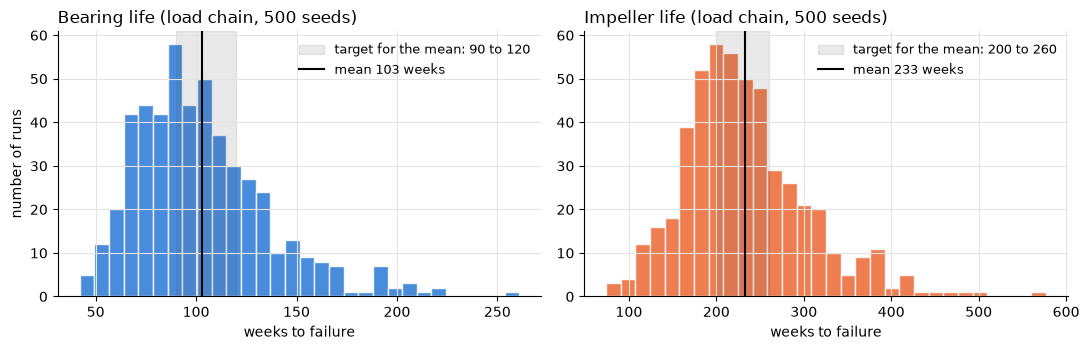

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, mode, band, color in [(axes[0], "bearing", (90, 120), BLUE), (axes[1], "impeller", (200, 260), ORANGE)]:
    life = chain.loc[chain["mode"] == mode, "life"]
    ax.hist(life, bins=30, color=color, alpha=0.85, edgecolor="white")
    ax.axvspan(*band, color=MUTED, alpha=0.12, label=f"target for the mean: {band[0]} to {band[1]}")
    ax.axvline(life.mean(), color="black", lw=1.5, label=f"mean {life.mean():.0f} weeks")
    ax.set_title(f"{mode.capitalize()} life (load chain, 500 seeds)", loc="left")
    ax.set_xlabel("weeks to failure")
    ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel("number of runs")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "twin_lifetimes.png")
plt.show()

Both wear laws use load squared (affinity laws). If the wear rate grows with load squared, life should fall as 1 / load squared. The table compares the mean life at each fixed load with this rule, scaled from the measured life at 0.75

In [5]:
fixed = lives[lives["load"] != "chain"].copy()
fixed["load"] = fixed["load"].astype(float)
load_table = fixed.pivot_table(index="load", columns="mode", values="life", aggfunc="mean")
for mode in ["bearing", "impeller"]:
    load_table[f"{mode} (1/load² rule)"] = load_table.loc[0.75, mode] * (0.75 / load_table.index) ** 2
load_table.round(1)

mode,bearing,impeller,bearing (1/load² rule),impeller (1/load² rule)
load,,,,
0.60,160.8,369.7,162.6,370.3
0.75,104.1,237.0,104.1,237.0
0.90,73.0,164.7,72.3,164.6


**Result:** mean bearing life is 102.9 weeks (standard error 1.5) and mean impeller life is 232.7 weeks (standard error 3.2). Both are inside their targets and close to the design values 104 and 230. The spread is about ±32% (coefficient of variation 0.32 and 0.31), close to the ±30% in the parameter table

With both modes on, the pump fails for the first time after 101.6 weeks on average (about 2 years) and 10% of pumps fail before week 69

Load works as intended: mean life follows the 1 / load² rule within 1.1% for the bearing and 0.2% for the impeller. The small gap for the bearing comes from taking weekly steps on an exponential law. A pump at load 0.90 lasts only about 70% as long as at load 0.75, so the agent needs the load in its observation

## 3. Sensors against the hidden wear

The agent never sees the wear. It only sees load, vibration, bearing temperature and efficiency. A sensor is useful when it changes steadily as the wear grows (the health indicator idea from the course Predictive Maintenance deck)

First, load also moves vibration and temperature. The table shows healthy pumps (bearing wear below 0.1) at each load level

In [6]:
healthy = runs[runs["bearing_wear"] < 0.1]
healthy.groupby("load")[["vibration", "temperature", "efficiency"]].agg(["mean", "std"]).round(3)

vibration        temperature        efficiency      
          mean    std        mean    std       mean   std
load                                                     
0.60     2.175  0.210      58.604  1.013      0.789  0.01
0.75     2.293  0.213      60.622  0.996      0.789  0.01
0.90     2.419  0.212      63.100  1.001      0.789  0.01

To remove the load effect we subtract the reading a new pump gives at the same load. In a plant these normal values would be recorded once per load level after commissioning. We call the results **excess vibration** and **excess temperature**

In [7]:
vib_clean, temp_clean, eff_clean = sensor_values(p, runs["load"], runs["bearing_wear"], runs["impeller_wear"])
vib_new, temp_new, _ = sensor_values(p, runs["load"], 0.0, 0.0)
runs["vib_excess"] = runs["vibration"] - vib_new
runs["temp_excess"] = runs["temperature"] - temp_new
runs["vib_excess_clean"] = vib_clean - vib_new
runs["temp_excess_clean"] = temp_clean - temp_new
runs["eff_clean"] = eff_clean


def rank_corr(x, y):
    return x.rank().corr(y.rank())


signals = ["vibration", "vib_excess", "temperature", "temp_excess", "efficiency", "load"]
trend = pd.DataFrame({
    "bearing wear": [rank_corr(runs[s], runs["bearing_wear"]) for s in signals],
    "impeller wear": [rank_corr(runs[s], runs["impeller_wear"]) for s in signals],
}, index=signals)
trend.round(3)

,bearing wear,impeller wear
vibration,0.825,0.710
vib_excess,0.838,0.725
temperature,0.345,0.237
temp_excess,0.411,0.290
efficiency,-0.782,-0.936
load,0.010,0.001


Rank correlation only says whether a signal moves in the same direction as the wear. The next table shows how the median excess readings change across bearing wear bands, which shows where in the life each sensor starts to respond

In [8]:
bands = pd.cut(runs["bearing_wear"], np.arange(0, 1.01, 0.1))
band_table = runs.groupby(bands, observed=True)[["vib_excess", "temp_excess"]].median()
band_table["weeks in band"] = runs.groupby(bands, observed=True).size()
band_table.round(2)

,vib_excess,temp_excess,weeks in band
bearing_wear,,,
"(0.0, 0.1]",0.09,0.01,26087
"(0.1, 0.2]",0.33,-0.00,7125
"(0.2, 0.3]",0.65,0.04,4321
"(0.3, 0.4]",1.09,0.15,3104
"(0.4, 0.5]",1.67,0.60,2380
"(0.5, 0.6]",2.37,1.54,1922
"(0.6, 0.7]",3.22,3.47,1638
"(0.7, 0.8]",4.23,7.06,1404
"(0.8, 0.9]",5.33,13.31,1242


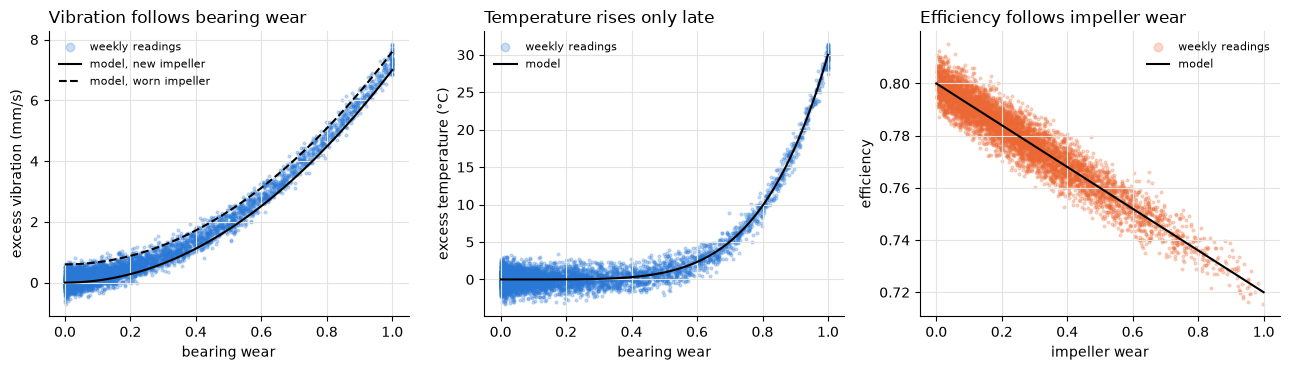

In [9]:
sample = runs.sample(6000, random_state=0)
b = np.linspace(0, 1, 101)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

axes[0].scatter(sample["bearing_wear"].clip(upper=1), sample["vib_excess"], s=4, color=BLUE, alpha=0.25, label="weekly readings")
axes[0].plot(b, p["vib_bearing"] * b**2, color="black", lw=1.5, label="model, new impeller")
axes[0].plot(b, p["vib_bearing"] * b**2 + p["vib_impeller"], color="black", lw=1.5, ls="--", label="model, worn impeller")
axes[0].set_xlabel("bearing wear")
axes[0].set_ylabel("excess vibration (mm/s)")

axes[1].scatter(sample["bearing_wear"].clip(upper=1), sample["temp_excess"], s=4, color=BLUE, alpha=0.25, label="weekly readings")
axes[1].plot(b, p["temp_bearing"] * b ** p["temp_power"], color="black", lw=1.5, label="model")
axes[1].set_xlabel("bearing wear")
axes[1].set_ylabel("excess temperature (°C)")

axes[2].scatter(sample["impeller_wear"].clip(upper=1), sample["efficiency"], s=4, color=ORANGE, alpha=0.25, label="weekly readings")
axes[2].plot(b, p["eff_new"] - p["eff_loss"] * b, color="black", lw=1.5, label="model")
axes[2].set_xlabel("impeller wear")
axes[2].set_ylabel("efficiency")

for ax, title in zip(axes, ["Vibration follows bearing wear", "Temperature rises only late", "Efficiency follows impeller wear"]):
    ax.set_title(title, loc="left")
    ax.legend(frameon=False, fontsize=8, markerscale=3)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "twin_sensors_vs_wear.png")
plt.show()

**Result:**

- Load moves the healthy temperature by 4.5 °C between the lowest and the highest load, more than four times the sensor noise (1.0 °C). For vibration the shift is 0.24 mm/s, about the size of the noise (0.21). Subtracting the new pump value removes this effect and slightly raises the rank correlation with bearing wear (vibration 0.825 to 0.838, temperature 0.345 to 0.411)
- Vibration follows bearing wear steadily from early in the life (0.84). It also rises a little with impeller wear because of the 0.6·w term
- Temperature has a low correlation overall (0.41) because it stays flat for most of the life. The band table shows that it only moves after bearing wear passes 0.5 and then rises fast: about 7 °C in the band 0.7 to 0.8 and 23 °C in the band 0.9 to 1.0. It is a late but sharp sign
- Efficiency follows impeller wear closely (−0.94) and does not respond to the bearing. Its correlation with bearing wear (−0.78) only comes from both wears growing with time
- Load has no relation to the wear level (0.01), but it sets how fast the wear grows

All four signals stay in the observation. Vibration and temperature enter as excess values over a new pump at the same load

## 4. Warning time before a bearing failure

For every run that ends with a bearing failure, the lead time of a sign is the number of weeks between the first week the sign appears and the failure week. The signs are vibration in ISO zone C (above 5.0 mm/s), the vibration alarm (6.3 mm/s), a visible temperature rise (5 °C above normal for the load) and the temperature alarm (85 °C)

In [10]:
warn = bearing_warnings(runs)
leads = ["vib_zone_c", "vib_alarm", "temp_rise", "temp_alarm"]
print(f"bearing failures: {len(warn)}")
print(warn[leads].describe(percentiles=[0.1, 0.5, 0.9]).round(1).to_string())
print(f"\nvibration in zone C at least 4 weeks before failure: {(warn['vib_zone_c'] >= 4).mean():.1%}")
print(f"temperature rise not before vibration zone C: {(warn['temp_rise'] <= warn['vib_zone_c']).mean():.1%}")
print(f"temperature alarm not before vibration zone C: {(warn['temp_alarm'] <= warn['vib_zone_c']).mean():.1%}")
print(f"mean temperature in the failure week: {warn['temp_at_failure'].mean():.1f} °C")

bearing failures: 490
       vib_zone_c  vib_alarm  temp_rise  temp_alarm
count       490.0      490.0      490.0       490.0
mean         11.2        6.6        8.0         0.9
std           4.4        2.8        3.2         0.7
min           3.0        2.0        2.0         0.0
10%           6.0        3.0        4.0         0.0
50%          11.0        6.0        8.0         1.0
90%          17.0       10.0       12.0         2.0
max          31.0       17.0       20.0         4.0

vibration in zone C at least 4 weeks before failure: 99.6%
temperature rise not before vibration zone C: 99.6%
temperature alarm not before vibration zone C: 100.0%
mean temperature in the failure week: 91.1 °C


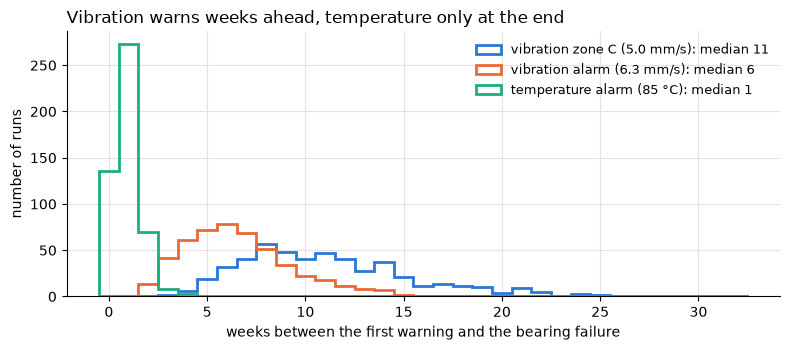

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.6))
edges = np.arange(0, warn["vib_zone_c"].max() + 3) - 0.5
for col, label, color in [("vib_zone_c", "vibration zone C (5.0 mm/s)", BLUE), ("vib_alarm", "vibration alarm (6.3 mm/s)", ORANGE),
                          ("temp_alarm", "temperature alarm (85 °C)", AQUA)]:
    ax.hist(warn[col], bins=edges, histtype="step", lw=2, color=color, label=f"{label}: median {warn[col].median():.0f}")
ax.set_xlabel("weeks between the first warning and the bearing failure")
ax.set_ylabel("number of runs")
ax.set_title("Vibration warns weeks ahead, temperature only at the end", loc="left")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "twin_warning_times.png")
plt.show()

Example runs: the shortest, a typical and a long bearing life among the 500 runs (10th, 50th and 90th percentile of time to failure)

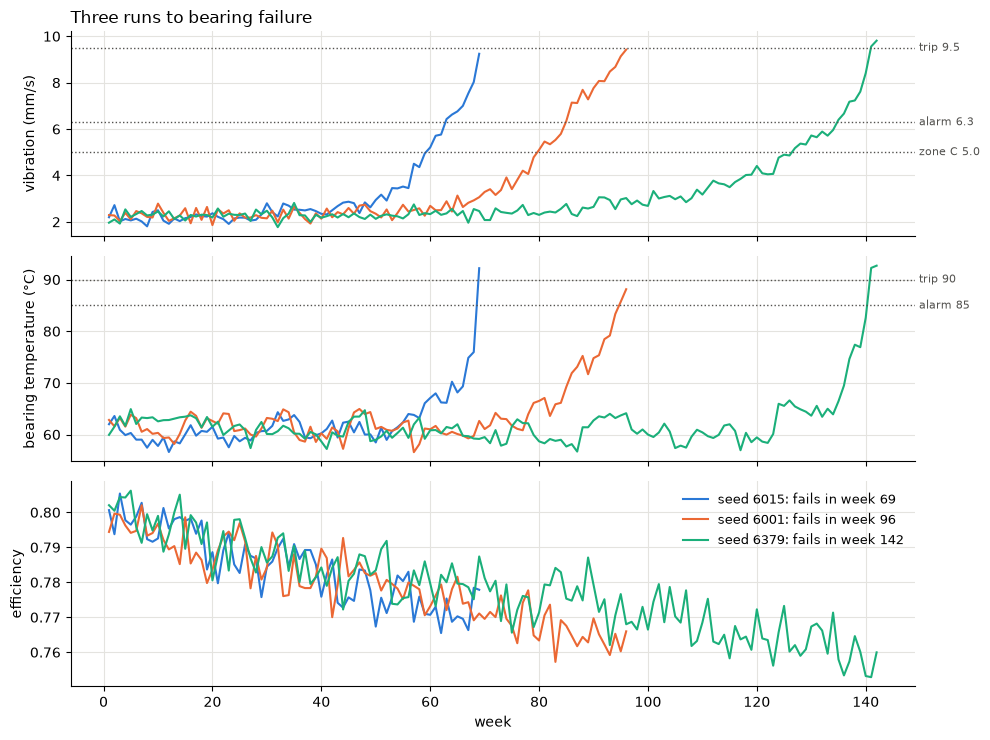

In [12]:
ttf_bearing = ttf[first == "bearing"]
picks = [(ttf_bearing - ttf_bearing.quantile(q)).abs().idxmin() for q in (0.1, 0.5, 0.9)]
fig, axes = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True)
for seed, color in zip(picks, [BLUE, ORANGE, AQUA]):
    run = runs[runs["seed"] == seed]
    label = f"seed {seed}: fails in week {run['week'].max()}"
    axes[0].plot(run["week"], run["vibration"], color=color, lw=1.5)
    axes[1].plot(run["week"], run["temperature"], color=color, lw=1.5)
    axes[2].plot(run["week"], run["efficiency"], color=color, lw=1.5, label=label)
for y, text in [(config.VIB_ZONES[1], "zone C 5.0"), (config.VIB_ALARM, "alarm 6.3"), (config.VIB_TRIP, "trip 9.5")]:
    axes[0].axhline(y, color=MUTED, lw=1, ls=":")
    axes[0].text(1.0, y, f" {text}", transform=axes[0].get_yaxis_transform(), va="center", fontsize=8, color=MUTED)
for y, text in [(config.TEMP_ALARM, "alarm 85"), (config.TEMP_TRIP, "trip 90")]:
    axes[1].axhline(y, color=MUTED, lw=1, ls=":")
    axes[1].text(1.0, y, f" {text}", transform=axes[1].get_yaxis_transform(), va="center", fontsize=8, color=MUTED)
axes[0].set_ylabel("vibration (mm/s)")
axes[1].set_ylabel("bearing temperature (°C)")
axes[2].set_ylabel("efficiency")
axes[2].set_xlabel("week")
axes[0].set_title("Three runs to bearing failure", loc="left")
axes[2].legend(frameon=False, fontsize=9, loc="upper right")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "twin_example_runs.png")
plt.show()

**Result:** over the 490 bearing failures:

- Vibration enters zone C a median of 11 weeks before failure (10% to 90%: 6 to 17 weeks) and passes the 6.3 mm/s alarm a median of 6 weeks before failure (3 to 10). In 99.6% of runs zone C comes at least 4 weeks before failure. The alarm lead matches the 4 to 8 week warning stage in source S8
- Temperature rises 5 °C above normal a median of 8 weeks before failure and passes the 85 °C alarm a median of 1 week before failure (10% to 90%: 0 to 2). In 28% of runs the alarm is only reached in the failure week. Temperature never warns before vibration has entered zone C (99.6% of runs for the rise, 100% for the alarm)
- The mean temperature in the failure week is 91.1 °C, at the 90 °C trip, just as vibration at failure is near its 9.5 mm/s trip

The warning order from Phase 1 holds: vibration first, temperature last. Between the first clear vibration sign and the failure the agent gets about 6 to 11 weekly decisions, so a weekly step is fine enough for this problem

## 5. Smoothing

A moving average over the last k weeks reduces sensor noise, but it also delays the signal. The right k depends on how fast the true signal changes compared with the noise

Since this is a simulation, we know the noise free reading of every week, so we can measure the error of each choice directly: the root mean square difference between the smoothed reading and the noise free reading. The selection rule is fixed before looking at the results:

- vibration and temperature: smallest error in the last 12 weeks before a bearing failure, because that is where maintenance decisions are made;
- efficiency: smallest error over the whole run, because it follows impeller wear, which changes slowly through the whole life

The average restarts at the start of each run, like it would restart after maintenance in the RL environment. The failure week itself is left out: after a failure the pump is repaired, so that reading is never used for a decision

In [13]:
runs["weeks_to_failure"] = runs.groupby("seed")["week"].transform("max") - runs["week"]
used = runs["weeks_to_failure"] > 0
end = used & (runs["failure"] == "bearing") & (runs["weeks_to_failure"] <= 12)
by_run = runs.groupby("seed")
pairs = {"vib_excess": "vib_excess_clean", "temp_excess": "temp_excess_clean", "efficiency": "eff_clean"}

rows = []
for k in [1, 2, 3, 4, 6, 8, 10, 12]:
    for signal, clean in pairs.items():
        smooth = by_run[signal].transform(lambda x: x.rolling(k, min_periods=1).mean())
        error = smooth - runs[clean]
        rows.append({"k": k, "signal": signal, "whole run": np.sqrt((error[used] ** 2).mean()),
                     "last 12 weeks": np.sqrt((error[end] ** 2).mean())})
smoothing = pd.DataFrame(rows)
smoothing.to_csv(config.TABLES_DIR / "twin_smoothing.csv", index=False)
smoothing.pivot(index="k", columns="signal", values=["whole run", "last 12 weeks"]).round(5)

whole run                        last 12 weeks                       
signal efficiency temp_excess vib_excess    efficiency temp_excess vib_excess
k                                                                            
1         0.00500     0.99771    0.19883       0.00497     0.98433    0.19633
2         0.00356     0.86097    0.16376       0.00350     1.59860    0.26661
3         0.00295     1.04818    0.19198       0.00285     2.60432    0.43636
4         0.00263     1.29588    0.23997       0.00252     3.50563    0.60708
6         0.00237     1.75521    0.34389       0.00225     4.97320    0.92087
8         0.00237     2.12440    0.44124       0.00225     6.09249    1.19775
10        0.00250     2.41700    0.52866       0.00241     6.96446    1.44126
12        0.00272     2.64974    0.60667       0.00267     7.65254    1.65629

chosen window (weeks): {'vib_excess': 1, 'temp_excess': 1, 'efficiency': 8}


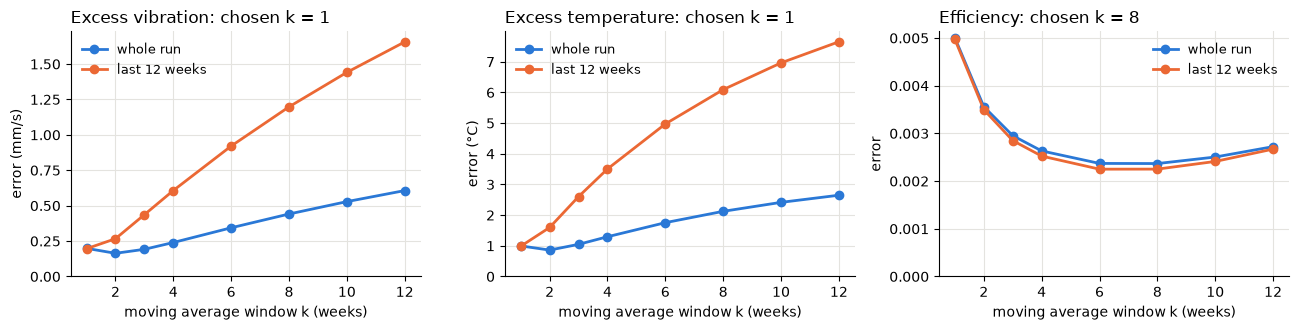

In [14]:
rule = {"vib_excess": "last 12 weeks", "temp_excess": "last 12 weeks", "efficiency": "whole run"}
best = {s: int(smoothing.loc[smoothing.loc[smoothing["signal"] == s, rule[s]].idxmin(), "k"]) for s in rule}
print("chosen window (weeks):", best)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, (signal, name, unit) in zip(axes, [("vib_excess", "Excess vibration", "mm/s"), ("temp_excess", "Excess temperature", "°C"),
                                           ("efficiency", "Efficiency", "")]):
    part = smoothing[smoothing["signal"] == signal]
    ax.plot(part["k"], part["whole run"], marker="o", color=BLUE, lw=2, label="whole run")
    ax.plot(part["k"], part["last 12 weeks"], marker="o", color=ORANGE, lw=2, label="last 12 weeks")
    ax.set_title(f"{name}: chosen k = {best[signal]}", loc="left")
    ax.set_xlabel("moving average window k (weeks)")
    ax.set_ylabel(f"error ({unit})" if unit else "error")
    ax.set_ylim(bottom=0)
    ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "twin_smoothing.png")
plt.show()

**Result:**

- **Vibration and temperature: no smoothing.** In the last 12 weeks before a bearing failure the raw reading has the smallest error (0.20 mm/s and 0.98 °C, which is just the sensor noise). A 2 week average already raises the error to 0.27 mm/s and 1.60 °C and a 4 week average to 0.61 mm/s and 3.51 °C. Near failure the true signal climbs faster each week than the noise, so averaging old readings adds more delay error than it removes noise. Over the whole run a 2 week average would be slightly better for vibration (0.164 against 0.199 mm/s), but in those weeks no decision depends on it
- **Efficiency: 8 week moving average.** Efficiency changes slowly, so averaging halves its error (0.0050 to 0.0024). Windows of 6 and 8 weeks are practically equal (0.002371 and 0.002368) and the rule picks 8. The impeller wear estimated from it is off by about 0.03

This changes decision D09, which planned smoothed vibration, temperature and efficiency. Only efficiency is smoothed. In the environment the efficiency average must restart after a major overhaul or a repair, because both renew the impeller. Minor maintenance does not change efficiency, so the average continues

## 6. Scaling for the RL observation

A neural network learns best when its inputs are on a similar scale, roughly 0 to 1. We scale each feature with physical limits rather than with the minimum and maximum of this data, so the same constants would work for real readings:

| Feature | Scaled value | 0 means | 1 means |
|---|---|---|---|
| excess vibration | excess / (trip 9.5 minus a new pump at load 0.75) | as new | about the trip level |
| excess temperature | excess / (trip 90 minus a new pump at load 0.75) | as new | about the trip level |
| efficiency (8 week average, section 5) | (0.80 minus efficiency) / 0.08 | new impeller | impeller end of life (0.72) |
| load | (load minus 0.60) / 0.30 | lowest load | highest load |
| bearing age | weeks since bearing renewal / 104 | new bearing | design bearing life |
| impeller age | weeks since impeller renewal / 230 | new impeller | design impeller life |

The age features belong to the environment (Phase 4). In these runs without maintenance both ages equal the week number

In [15]:
new_mid = sensor_values(p, 0.75, 0.0, 0.0)
vib_scale = config.VIB_TRIP - new_mid[0]
temp_scale = config.TEMP_TRIP - new_mid[1]
print(f"vibration scale {vib_scale:.2f} mm/s, temperature scale {temp_scale:.2f} °C")

eff_smooth = by_run["efficiency"].transform(lambda x: x.rolling(best["efficiency"], min_periods=1).mean())
features = pd.DataFrame({
    "vibration": runs["vib_excess"] / vib_scale,
    "temperature": runs["temp_excess"] / temp_scale,
    "impeller estimate": (p["eff_new"] - eff_smooth) / p["eff_loss"],
    "load": (runs["load"] - 0.60) / 0.30,
    "bearing age": runs["week"] / 104,
    "impeller age": runs["week"] / 230,
})
print(f"impeller estimate error against the true impeller wear: "
      f"{np.sqrt(((features['impeller estimate'] - runs['impeller_wear'].clip(upper=1)) ** 2).mean()):.3f}")
features.describe(percentiles=[0.01, 0.5, 0.99]).T.round(3)

vibration scale 7.30 mm/s, temperature scale 29.38 °C
impeller estimate error against the true impeller wear: 0.030


,count,mean,std,min,1%,50%,99%,max
vibration,50810.0,0.130,0.222,-0.100,-0.047,0.042,0.979,1.083
temperature,50810.0,0.052,0.173,-0.133,-0.076,0.009,0.984,1.140
impeller estimate,50810.0,0.249,0.190,-0.171,-0.029,0.214,0.818,0.999
load,50810.0,0.490,0.377,0.000,0.000,0.500,1.000,1.000
bearing age,50810.0,0.535,0.352,0.010,0.019,0.490,1.481,2.144
impeller age,50810.0,0.242,0.159,0.004,0.009,0.222,0.670,0.970


**Result:** the vibration scale is 7.30 mm/s and the temperature scale is 29.38 °C. Between the 1st and 99th percentile every sensor feature stays between −0.08 and 0.98 and load lies in [0, 1]. Values a little below 0 come from noise on a new pump. Values a little above 1 only appear in the last weeks before failure. The ages reach 2.1 here only because these runs have no maintenance; in the environment maintenance resets them

These constants are a proposal. They are fixed in Phase 4, when the environment builds the observation

## 7. Calibration targets on fresh seeds

The constants in `src/config.py` were chosen in `scripts/calibrate_twin.py` on the calibration seeds (5000 to 5299). Here we check every target again on the EDA seeds, which the calibration never used

In [16]:
rules = {
    "bearing_life": ("mean bearing life 90 to 120 weeks", "bearing_life_mean"),
    "impeller_life": ("mean impeller life 200 to 260 weeks", "impeller_life_mean"),
    "vib_c_4wk": ("zone C at least 4 weeks before failure in 90% of runs", "vib_c_4wk"),
    "vib_alarm": ("median vibration alarm lead 4 to 8 weeks", "vib_alarm_median"),
    "temp_flat": ("temperature rise not before zone C in 90% of runs", "temp_flat"),
    "temp_alarm": ("median temperature alarm lead 1 to 3 weeks", "temp_alarm_median"),
    "temp_alarm_after_vib": ("temperature alarm not before zone C in 90% of runs", "temp_alarm_after_vib"),
    "temp_at_failure": ("mean temperature at failure 88 to 98 °C", "temp_at_failure"),
}
metrics, passed = check_targets(p, config.EDA_SEEDS)
targets = pd.DataFrame([{"target": text, "measured": round(float(metrics[key]), 3), "passed": passed[name]}
                        for name, (text, key) in rules.items()])
assert set(rules) == set(TARGETS)
targets.to_csv(config.TABLES_DIR / "twin_targets.csv", index=False)
targets

,target,measured,passed
0,mean bearing life 90 to 120 weeks,102.854,True
1,mean impeller life 200 to 260 weeks,232.682,True
2,zone C at least 4 weeks before failure in 90% ...,0.996,True
3,median vibration alarm lead 4 to 8 weeks,6.000,True
4,temperature rise not before zone C in 90% of runs,0.996,True
5,median temperature alarm lead 1 to 3 weeks,1.000,True
6,temperature alarm not before zone C in 90% of ...,1.000,True
7,mean temperature at failure 88 to 98 °C,91.124,True


## 8. Summary

| Question | Answer |
|---|---|
| Data complete and physical? | Yes: no missing values; readings inside physical limits after limiting wear to 1 in the sensor equations |
| Lifetimes on target? | Yes: bearing 102.9 weeks, impeller 232.7 weeks, spread about ±32%; life follows 1 / load² |
| Do the sensors trend with wear? | Vibration and efficiency from early in life; temperature only in the last part of the bearing life, then sharply |
| Warning time before bearing failure | Vibration zone C median 11 weeks, vibration alarm 6 weeks, temperature alarm 1 week; vibration always warns first |
| Smoothing | None for vibration and temperature; 8 week moving average for efficiency |
| Observation (proposal for Phase 4) | excess vibration / 7.30, excess temperature / 29.38, impeller estimate from the 8 week efficiency, load scaled to 0 to 1, bearing age / 104, impeller age / 230 |
| Calibration targets on fresh seeds | 8 of 8 met (section 7) |

Known limits:

- The visible temperature rise comes a median of 8 weeks before failure, earlier than the 2 to 4 weeks in source S8. This target was relaxed in Phase 3 because it could not be met together with the alarm target
- In 28% of bearing failures the temperature alarm is only reached in the failure week. Vibration still warns in these runs
- The twin does not stop the pump automatically at the trip limits. Failure happens when wear reaches 1, which is about when both readings reach their trip levels